# SciPy Community Software Analysis

**Aditya Gupta**

For my community software analysis, I chose SciPy, an open source Python library used for scientific and numerical computing. SciPy includes tools for optimization, rootfinding, integration, interpolation, linear algebra, statistics, and many other numerical problems.

I chose SciPy because it connects to a lot of the topics we have covered in class, and it is also a Python library that I could see myself using in other projects. Since SciPy is a very large library, I decided to focus on its linear algebra tools and how conditioning can affect the accuracy of solving a linear system.

## About SciPy

SciPy started in 2001 and has grown into a large open source project with contributors from many different organizations and universities. Development mainly happens through GitHub issues and pull requests, along with discussions on the Scientific Python forum.

The project uses automated testing and continuous integration to check new changes. SciPy also has a contribution guide and an AI contribution policy.

For this project, I am mainly interested in `scipy.linalg`, which contains tools for solving linear systems, matrix decompositions, eigenvalue problems, and other linear algebra operations.

## Conditioning and Linear Systems

A linear system can be written as

\[
Ax=b
\]

where we are trying to find the vector \(x\).

One thing that can make this harder is the condition number of the matrix \(A\). A matrix with a small condition number is usually less sensitive to small errors. A matrix with a very large condition number is poorly conditioned, meaning that small rounding errors or small changes in the inputs can cause a much larger change in the solution.

I wanted to see how this shows up when using SciPy to solve linear systems.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.linalg import solve, hilbert

print("SciPy version:", scipy.__version__)

SciPy version: 1.14.1


## A Small Example

I will start with a Hilbert matrix. Hilbert matrices are useful for this example because they become poorly conditioned as their size increases.

I will choose the correct solution myself first, then calculate \(b\). This means I already know what the answer should be before asking SciPy to solve the system.

In [2]:
n = 5

A = hilbert(n)

x_true = np.ones(n)

b = A @ x_true

x_scipy = solve(A, b)

condition_number = np.linalg.cond(A)

relative_error = (
    np.linalg.norm(x_scipy - x_true)
    / np.linalg.norm(x_true)
)

print("Matrix A:")
print(A)

print("\nTrue solution:")
print(x_true)

print("\nSciPy solution:")
print(x_scipy)

print("\nCondition number:")
print(condition_number)

print("\nRelative error:")
print(relative_error)

Matrix A:
[[1.         0.5        0.33333333 0.25       0.2       ]
 [0.5        0.33333333 0.25       0.2        0.16666667]
 [0.33333333 0.25       0.2        0.16666667 0.14285714]
 [0.25       0.2        0.16666667 0.14285714 0.125     ]
 [0.2        0.16666667 0.14285714 0.125      0.11111111]]

True solution:
[1. 1. 1. 1. 1.]

SciPy solution:
[1. 1. 1. 1. 1.]

Condition number:
476607.2502419338

Relative error:
1.256825919192874e-12


For this smaller matrix, SciPy gets very close to the solution I originally used. The relative error is very small.

However, the Hilbert matrix becomes much more poorly conditioned as its size increases. I wanted to see whether the error in SciPy's solution also changes as the condition number gets larger.

In [7]:
import warnings
from scipy.linalg import LinAlgWarning

sizes = range(2, 13)

condition_numbers = []
errors = []

for n in sizes:
    A = hilbert(n)

    x_true = np.ones(n)
    b = A @ x_true

    # Catch SciPy's warning for poorly conditioned matrices
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", LinAlgWarning)
        x_scipy = solve(A, b)

    condition_number = np.linalg.cond(A)

    relative_error = (
        np.linalg.norm(x_scipy - x_true)
        / np.linalg.norm(x_true)
    )

    condition_numbers.append(condition_number)
    errors.append(relative_error)

    print(
        f"n = {n:2d} | "
        f"condition number = {condition_number:.2e} | "
        f"relative error = {relative_error:.2e}"
    )

n =  2 | condition number = 1.93e+01 | relative error = 5.66e-16
n =  3 | condition number = 5.24e+02 | relative error = 8.35e-15
n =  4 | condition number = 1.55e+04 | relative error = 3.37e-14
n =  5 | condition number = 4.77e+05 | relative error = 1.26e-12
n =  6 | condition number = 1.50e+07 | relative error = 4.08e-11
n =  7 | condition number = 4.75e+08 | relative error = 1.77e-09
n =  8 | condition number = 1.53e+10 | relative error = 6.74e-08
n =  9 | condition number = 4.93e+11 | relative error = 3.00e-06
n = 10 | condition number = 1.60e+13 | relative error = 1.25e-05
n = 11 | condition number = 5.22e+14 | relative error = 1.13e-03
n = 12 | condition number = 1.64e+16 | relative error = 1.29e-01


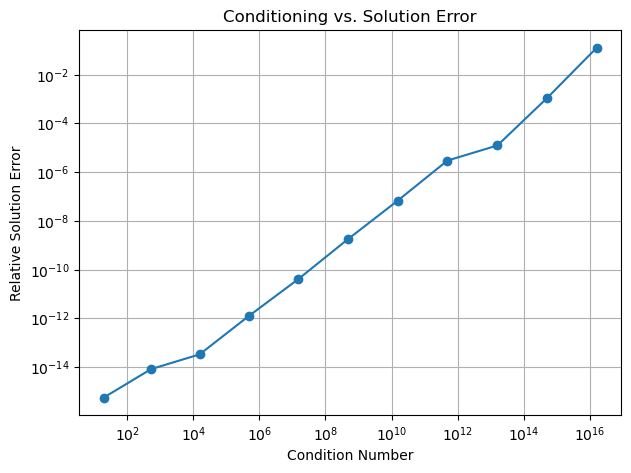

In [4]:
plt.figure(figsize=(7, 5))

plt.loglog(
    condition_numbers,
    errors,
    "o-"
)

plt.xlabel("Condition Number")
plt.ylabel("Relative Solution Error")
plt.title("Conditioning vs. Solution Error")
plt.grid(True)

plt.show()

## What I Found

As the size of the Hilbert matrix increases, its condition number increases very quickly. I can also see that the error in the solution generally becomes larger.

What I found interesting is that SciPy can still be using a good numerical algorithm, but the answer can become less accurate because the problem itself is very sensitive to small errors. This connects to the difference between conditioning and numerical stability that we have talked about in class.

The condition number describes the sensitivity of the problem, while numerical stability is more about how much extra error the algorithm introduces while solving it.

## Question About SciPy

One question I still have is:

**How does SciPy decide which underlying algorithm or LAPACK routine to use when `scipy.linalg.solve` is called, and can that choice affect the accuracy of the solution for poorly conditioned matrices?**

## Possible Group Experiment

For a group project, I think it would be interesting to test how both the condition number and floating-point precision affect SciPy's ability to solve linear systems.

We could generate matrices with different condition numbers and solve the same type of system using both `float32` and `float64`. For each problem, we could measure the relative error of the solution and how long the solve takes.

I would present the results using two plots:

1. **Condition number vs. relative solution error**
   - x-axis: Condition number
   - y-axis: Relative solution error
   - Separate lines for `float32` and `float64`

2. **Condition number vs. runtime**
   - x-axis: Condition number
   - y-axis: Runtime in milliseconds
   - Separate lines for `float32` and `float64`

This could help show when using higher precision actually makes a noticeable difference and what cost comes with it.